# Theta Method for Time Series Forecasting

This notebook explains the Theta method, implements the classical two-theta construction from scratch, uses the seasonal `statsmodels` ThetaModel, and compares forecasts with Naive, SES, and Holt.

Learning objectives:
- Understand theta lines and the classical θ = 0 / θ = 2 combination.
- Build and evaluate a Theta forecast.
- Handle seasonality through deseasonalization.
- Use chronological validation and test sets.
- Interpret the method for retail and supply-chain demand.

## 1. Intuition and equations

A theta line modifies the curvature (second differences) of a time series. A useful representation is:

`Z_t(θ) = θ × Y_t + (1 − θ) × (a + b × t)`

where `Y_t` is the observation and `a + b × t` is a fitted linear trend.

The classical two-theta construction uses:
- **θ = 0:** `Z_t(0) = a + b × t`, the linear trend component.
- **θ = 2:** `Z_t(2) = 2 × Y_t − (a + b × t)`, the curvature-amplified component.

The θ = 0 component is extrapolated as a linear trend. The θ = 2 component is forecast using Simple Exponential Smoothing (SES). The final forecast is the equal-weighted combination:

`Theta Forecast(h) = 0.5 × Trend Forecast(h) + 0.5 × SES Forecast of θ=2 series(h)`

The SES update is `L_t = α × Z_t(2) + (1 − α) × L_(t−1)`. Its multi-step forecast is flat at the final smoothed level.

This classical explanation is distinct from implementation details in individual software packages. Seasonal adjustment, initialization, and parameter estimation can vary.

## 2. Install and import libraries

Install if needed: `pip install numpy pandas matplotlib scikit-learn statsmodels`

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from statsmodels.tsa.seasonal import seasonal_decompose

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 5)

## 3. Create synthetic monthly demand

The series contains a gradual upward trend, annual seasonality, and random noise.

In [2]:
n_periods = 120
dates = pd.date_range("2016-01-01", periods=n_periods, freq="MS")
trend = 250 + 1.4 * np.arange(n_periods)
seasonal_pattern = np.array([-25, -18, -10, -3, 8, 18, 25, 22, 12, 2, 15, 35])
seasonality = np.tile(seasonal_pattern, n_periods // 12)
noise = np.random.normal(0, 12, n_periods)
series = pd.Series(trend + seasonality + noise, index=dates, name="Demand")
series.head()

2016-01-01    230.960570
2016-02-01    231.740828
2016-03-01    250.572262
2016-04-01    269.476358
2016-05-01    260.790160
Freq: MS, Name: Demand, dtype: float64

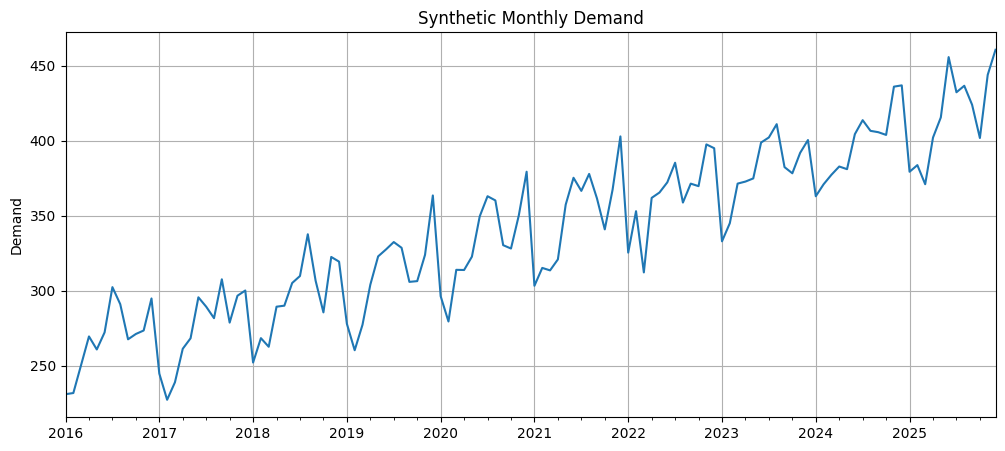

count    120.000000
mean     339.099971
std       55.565343
min      227.240637
25%      296.135307
50%      335.262707
75%      379.294589
max      460.623196
Name: Demand, dtype: float64


In [3]:
series.plot(title="Synthetic Monthly Demand", grid=True)
plt.ylabel("Demand")
plt.show()
print(series.describe())

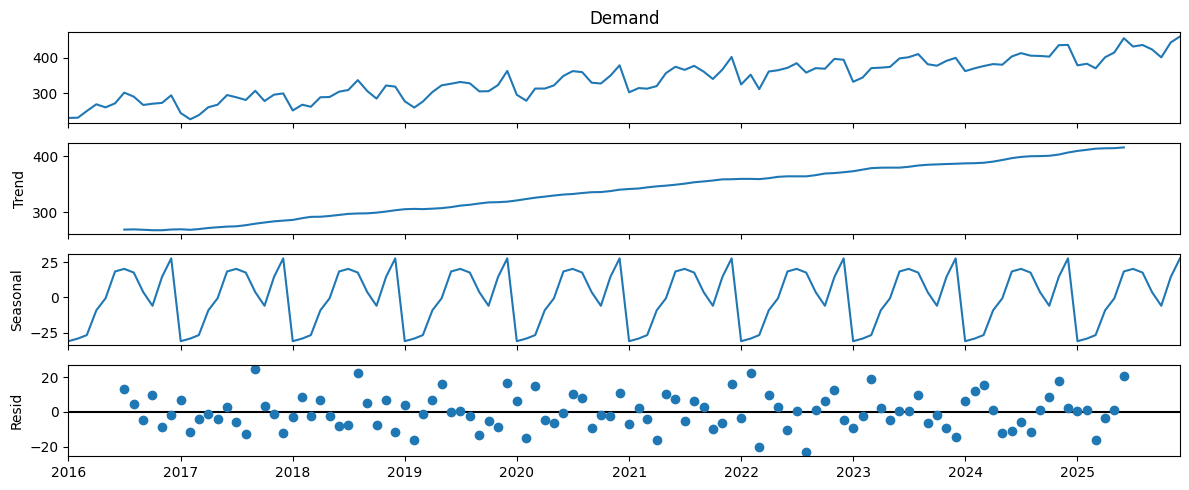

In [4]:
decomposition = seasonal_decompose(series, model="additive", period=12)
decomposition.plot()
plt.show()

## 4. Chronological train / validation / test split

We use 70% for training, 15% for validation, and 15% for final testing. Time-series data must not be randomly shuffled.

In [5]:
n = len(series)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train = series.iloc[:train_end]
validation = series.iloc[train_end:val_end]
test = series.iloc[val_end:]
print("Train:", len(train), train.index.min(), "to", train.index.max())
print("Validation:", len(validation), validation.index.min(), "to", validation.index.max())
print("Test:", len(test), test.index.min(), "to", test.index.max())

Train: 84 2016-01-01 00:00:00 to 2022-12-01 00:00:00
Validation: 18 2023-01-01 00:00:00 to 2024-06-01 00:00:00
Test: 18 2024-07-01 00:00:00 to 2025-12-01 00:00:00


## 5. Classical two-theta implementation from scratch

Steps:
1. Fit a linear regression to the training observations.
2. Construct the θ = 2 series: `2 × actual − fitted trend`.
3. Fit SES to this transformed series.
4. Extrapolate the θ = 0 linear trend.
5. Average the two component forecasts with equal weights.

This is an educational implementation of the classical construction. It is not guaranteed to reproduce every package's implementation exactly.

In [6]:
def classical_theta_forecast(y, horizon, smoothing_level=None):
    y = pd.Series(y).astype(float).reset_index(drop=True)
    if len(y) < 3 or horizon < 1:
        raise ValueError("Provide at least 3 observations and a positive horizon.")

    t = np.arange(len(y))
    slope, intercept = np.polyfit(t, y.values, 1)
    fitted_trend = intercept + slope * t
    theta_2 = 2 * y.values - fitted_trend

    ses = SimpleExpSmoothing(
        pd.Series(theta_2), initialization_method="estimated"
    )
    if smoothing_level is None:
        ses_fit = ses.fit(optimized=True)
    else:
        ses_fit = ses.fit(smoothing_level=smoothing_level, optimized=False)

    future_t = np.arange(len(y), len(y) + horizon)
    theta_0_forecast = intercept + slope * future_t
    theta_2_forecast = np.asarray(ses_fit.forecast(horizon))
    combined = 0.5 * theta_0_forecast + 0.5 * theta_2_forecast

    return pd.Series(combined), {
        "slope": slope, "intercept": intercept,
        "fitted_trend": fitted_trend, "theta_2_series": theta_2,
        "theta_0_forecast": theta_0_forecast,
        "theta_2_forecast": theta_2_forecast, "ses_fit": ses_fit
    }

In [7]:
theta_classic_val, theta_parts = classical_theta_forecast(train, len(validation))
print("Trend slope:", round(theta_parts["slope"], 4))
print("First five trend component forecasts:", np.round(theta_parts["theta_0_forecast"][:5], 2))
print("First five SES component forecasts:", np.round(theta_parts["theta_2_forecast"][:5], 2))
print("First five combined forecasts:", np.round(theta_classic_val.values[:5], 2))

Trend slope: 1.5105
First five trend component forecasts: [377.79 379.3  380.81 382.32 383.83]
First five SES component forecasts: [402.16 402.16 402.16 402.16 402.16]
First five combined forecasts: [389.97 390.73 391.48 392.24 392.99]


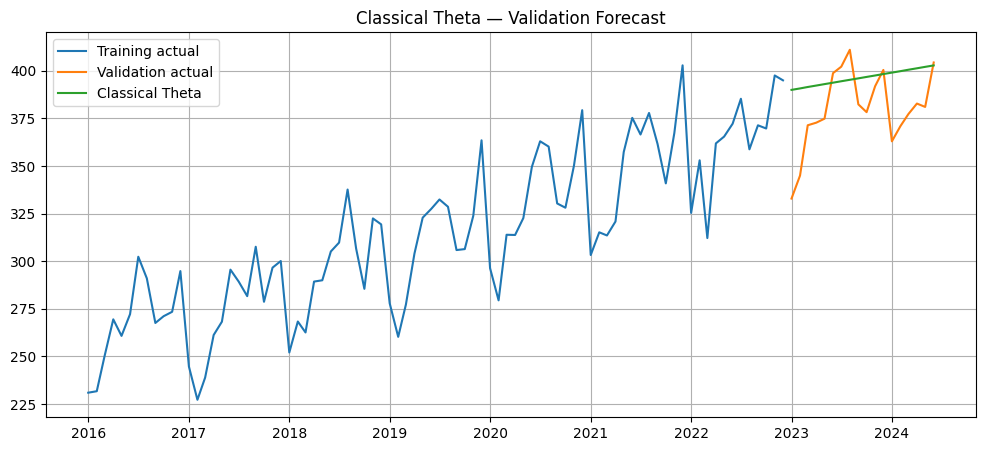

In [8]:
plt.plot(train, label="Training actual")
plt.plot(validation, label="Validation actual")
plt.plot(validation.index, theta_classic_val.values, label="Classical Theta")
plt.title("Classical Theta — Validation Forecast")
plt.legend()
plt.grid(True)
plt.show()

## 6. Seasonal Theta using statsmodels

For monthly data with annual seasonality, use `period=12` and `deseasonalize=True`. The model estimates the seasonal adjustment, forecasts the adjusted series, and restores seasonal effects.

In [9]:
theta_sm = ThetaModel(train, period=12, deseasonalize=True, use_test=True)
theta_sm_fit = theta_sm.fit()
theta_sm_val = theta_sm_fit.forecast(len(validation))
theta_sm_val.index = validation.index
theta_sm_val.head()

2023-01-01    333.228502
2023-02-01    332.328883
2023-03-01    335.790028
2023-04-01    360.908068
2023-05-01    374.202253
Freq: MS, Name: forecast, dtype: float64

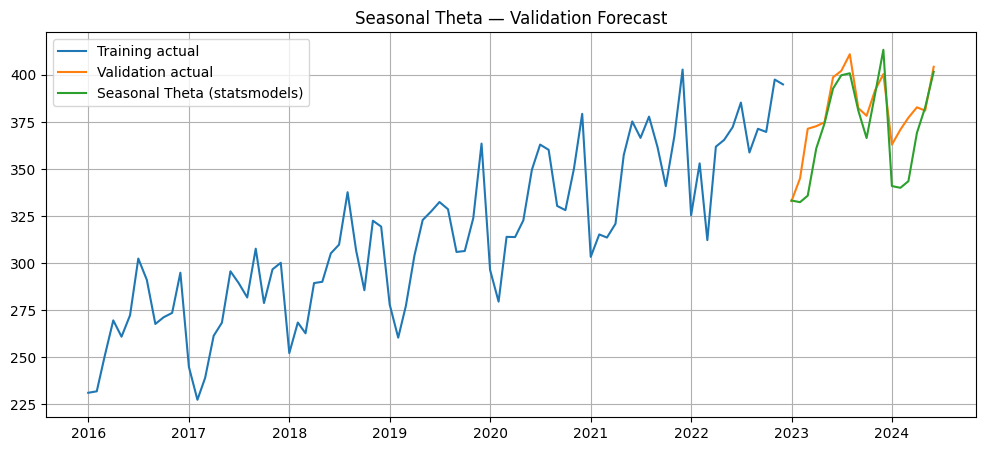

In [10]:
plt.plot(train, label="Training actual")
plt.plot(validation, label="Validation actual")
plt.plot(theta_sm_val, label="Seasonal Theta (statsmodels)")
plt.title("Seasonal Theta — Validation Forecast")
plt.legend()
plt.grid(True)
plt.show()

## 7. Compare with benchmark methods

We compare Naive, SES, Holt, the classical two-theta implementation, and seasonal Theta. All models use the same training history and validation horizon.

In [11]:
def naive_forecast(y, h):
    return np.repeat(float(y.iloc[-1]), h)

def ses_forecast(y, h):
    fit = SimpleExpSmoothing(y, initialization_method="estimated").fit(optimized=True)
    return np.asarray(fit.forecast(h))

def holt_forecast(y, h):
    fit = Holt(y, initialization_method="estimated").fit(optimized=True)
    return np.asarray(fit.forecast(h))

validation_forecasts = {
    "Naive": naive_forecast(train, len(validation)),
    "SES": ses_forecast(train, len(validation)),
    "Holt": holt_forecast(train, len(validation)),
    "Classical Theta": theta_classic_val.values,
    "Seasonal Theta (statsmodels)": theta_sm_val.values
}

## 8. Evaluation metrics

- **MAE:** average absolute error in demand units.
- **RMSE:** gives larger errors more weight.
- **WMAPE:** total absolute error divided by total actual demand.
- **Mean Error / Bias:** positive means over-forecasting on average.

MAPE can be unstable or undefined when actual demand is zero or close to zero.

In [12]:
def metrics(actual, forecast):
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    denom = np.sum(np.abs(actual))
    return {
        "MAE": mean_absolute_error(actual, forecast),
        "RMSE": np.sqrt(mean_squared_error(actual, forecast)),
        "WMAPE (%)": np.sum(np.abs(actual - forecast)) / denom * 100 if denom else np.nan,
        "Mean Error": np.mean(forecast - actual)
    }

val_rows = []
for name, pred in validation_forecasts.items():
    val_rows.append({"Model": name, **metrics(validation.values, pred)})
val_metrics = pd.DataFrame(val_rows).set_index("Model").sort_values("WMAPE (%)")
val_metrics.round(3)

,MAE,RMSE,WMAPE (%),Mean Error
Model,,,,
Seasonal Theta (statsmodels),11.798,16.337,3.104,-10.129
Holt,17.047,20.624,4.485,10.566
SES,17.637,22.122,4.640,10.152
Naive,19.569,24.677,5.149,14.921
Classical Theta,19.903,24.524,5.237,16.332


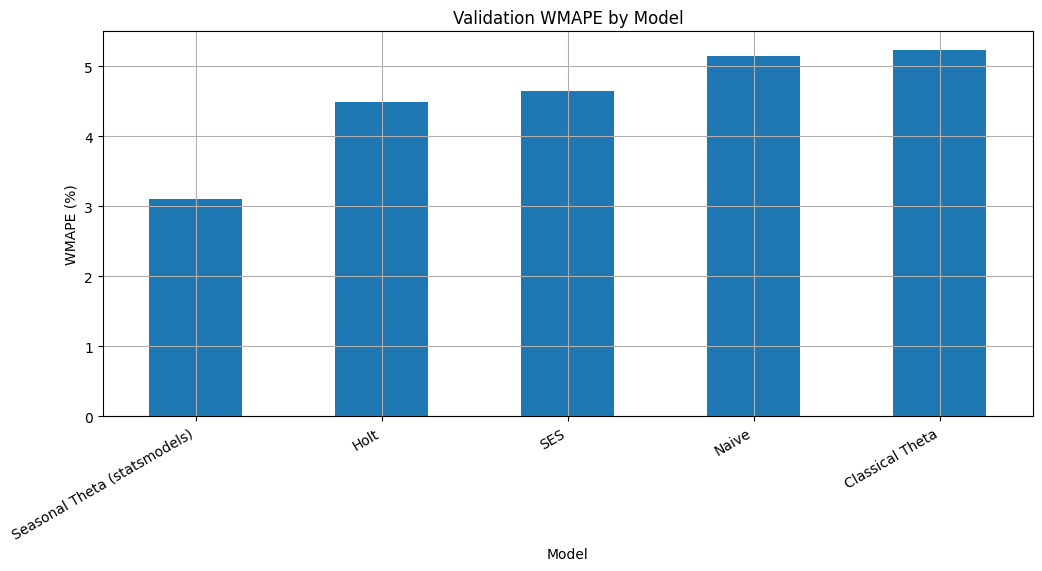

Lowest validation WMAPE: Seasonal Theta (statsmodels)


In [13]:
val_metrics["WMAPE (%)"].plot(kind="bar", title="Validation WMAPE by Model", grid=True)
plt.ylabel("WMAPE (%)")
plt.xticks(rotation=30, ha="right")
plt.show()
print("Lowest validation WMAPE:", val_metrics["WMAPE (%)"].idxmin())

## 9. Final test evaluation

Refit on training + validation history, then forecast the untouched test horizon. The test set is used only for final evaluation.

In [14]:
development = pd.concat([train, validation])
h = len(test)
final_predictions = {
    "Naive": naive_forecast(development, h),
    "SES": ses_forecast(development, h),
    "Holt": holt_forecast(development, h),
    "Classical Theta": classical_theta_forecast(development, h)[0].values
}
final_theta_sm = ThetaModel(
    development, period=12, deseasonalize=True, use_test=True
).fit()
final_predictions["Seasonal Theta (statsmodels)"] = np.asarray(final_theta_sm.forecast(h))

test_rows = [{"Model": name, **metrics(test.values, pred)}
             for name, pred in final_predictions.items()]
test_metrics = pd.DataFrame(test_rows).set_index("Model").sort_values("WMAPE (%)")
test_metrics.round(3)

,MAE,RMSE,WMAPE (%),Mean Error
Model,,,,
Seasonal Theta (statsmodels),16.341,18.600,3.917,-14.969
Holt,19.783,23.555,4.742,-6.605
Naive,22.210,27.932,5.324,-12.828
Classical Theta,27.656,32.443,6.629,-22.421
SES,29.643,35.130,7.105,-24.869


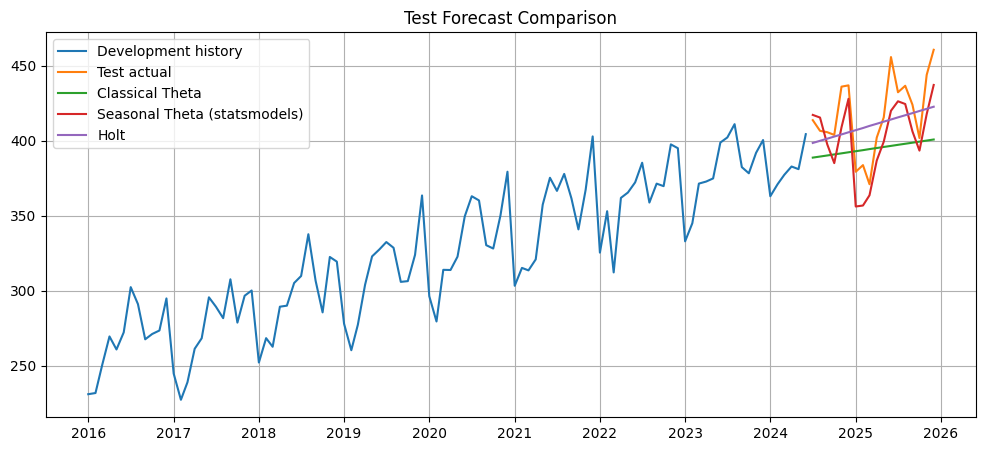

In [15]:
plt.plot(development, label="Development history")
plt.plot(test, label="Test actual")
for name in ["Classical Theta", "Seasonal Theta (statsmodels)", "Holt"]:
    plt.plot(test.index, final_predictions[name], label=name)
plt.title("Test Forecast Comparison")
plt.legend()
plt.grid(True)
plt.show()

## 10. Forecast the next 12 months

After model evaluation, refit the chosen configuration on all available history. This example demonstrates a seasonal Theta forecast for the next year.

In [16]:
final_model = ThetaModel(series, period=12, deseasonalize=True, use_test=True).fit()
future = final_model.forecast(12)
future.index = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
future

2026-01-01    383.467810
2026-02-01    385.350993
2026-03-01    390.147365
2026-04-01    413.431305
2026-05-01    424.928323
2026-06-01    449.024199
2026-07-01    453.917925
2026-08-01    451.238958
2026-09-01    433.774726
2026-10-01    421.393487
2026-11-01    448.082709
2026-12-01    466.203799
Freq: MS, Name: forecast, dtype: float64

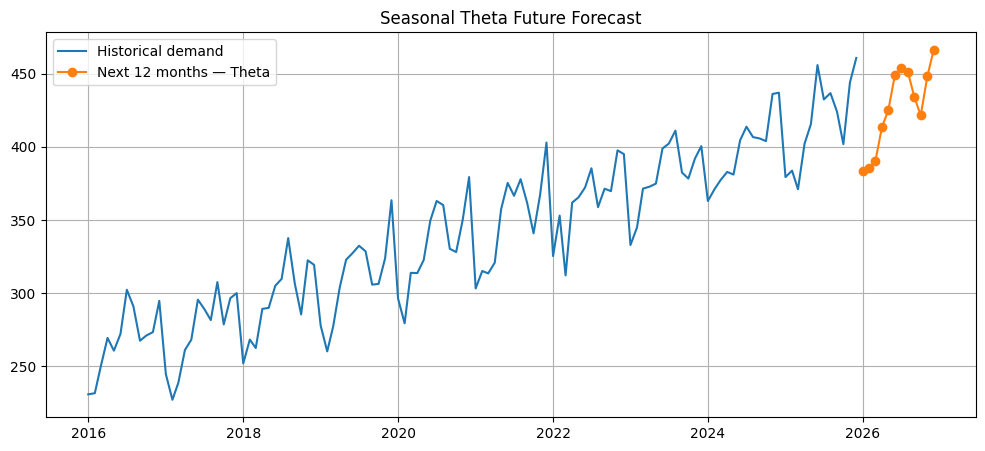

In [17]:
plt.plot(series, label="Historical demand")
plt.plot(future, marker="o", label="Next 12 months — Theta")
plt.title("Seasonal Theta Future Forecast")
plt.legend()
plt.grid(True)
plt.show()

## 11. Advantages

1. Relatively simple and interpretable combination of trend and smoothing.
2. Computationally efficient for univariate forecasting.
3. Useful statistical benchmark.
4. Seasonal adjustment is available in common implementations.
5. Can work well for relatively smooth series.

## 12. Limitations

1. Not the best choice for every time series.
2. Linear trend extrapolation can fail when the trend changes.
3. Seasonal period and adjustment must be selected carefully.
4. Basic Theta does not directly use price, promotions, weather, or event regressors.
5. Structural breaks and abrupt demand changes can reduce accuracy.
6. Software implementations may differ in initialization, estimation, and seasonal handling.

## 13. Supply-chain applications

- Baseline forecasts for item-location demand with a gradual trend.
- Benchmarking statistical models against machine-learning approaches.
- Forecasting product families with recurring seasonal patterns.
- Establishing a univariate baseline before incorporating promotion, price, weather, and event drivers.

For highly intermittent demand, consider Croston, SBA, or TSB. For strong trend and seasonality, compare against Holt-Winters.

## 14. Theta compared with other methods

| Method | Main components | Typical use |
|---|---|---|
| Naive | Last observation | Baseline |
| SES | Level | Stable level |
| Holt | Level + trend | Trend without seasonality |
| Holt-Winters | Level + trend + seasonality | Seasonal trend |
| Theta | Trend and SES-based components | Smooth series / benchmark |
| Croston, SBA, TSB | Occurrence and/or non-zero size | Intermittent demand |

## 15. Common mistakes

- Randomly shuffling time-series observations.
- Tuning against the test set.
- Choosing an incorrect seasonal period.
- Comparing models on different forecast horizons.
- Assuming Theta always beats Holt or Holt-Winters.
- Assuming the educational two-theta code exactly matches every package.

## 16. Key takeaway

The Theta method combines a linear-trend component and an exponentially smoothed component. It is an efficient statistical forecasting candidate and a useful benchmark. Always evaluate it alongside simple baselines and other suitable models using chronological validation and business-relevant metrics.